Library Imports & Setup

In [9]:
!pip install -q xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split, KFold, RepeatedKFold, cross_val_score,
    cross_validate, GridSearchCV, RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed — skipping XGBRegressor. Run 'pip install xgboost' if you want it.")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

Upload dataset

In [18]:
from google.colab import files

CSV_PATH = "/content/Concrete_Data.csv"
df_raw = pd.read_csv(CSV_PATH)
df_raw.columns = [c.strip() for c in df_raw.columns]
df = df_raw.copy()

# Target and feature setup
TARGETS = ["fck(MPa)"]
CAT_COLS = []
NUM_FEATURES = [c for c in df.columns if c not in TARGETS + CAT_COLS]

Data Checks

In [20]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Cement (Kg/m3)              1030 non-null   float64
 1   Blast Furnace Slag (Kg/m3)  1030 non-null   float64
 2   Fly Ash (Kg/m3)             1030 non-null   float64
 3   Water (Kg/m3)               1030 non-null   float64
 4   Superplasticizer (Kg/m3)    1030 non-null   float64
 5   Coarse Aggregate (Kg/m3)    1030 non-null   float64
 6   Fine Aggregate (Kg/m3)      1030 non-null   float64
 7   Age (day)                   1030 non-null   int64  
 8   fck(MPa)                    1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Missing values per column:
 Cement (Kg/m3)                0
Blast Furnace Slag (Kg/m3)    0
Fly Ash (Kg/m3)               0
Water (Kg/m3)                 0
Superplasticizer (Kg/m3)      0
Coarse Aggregate (Kg/m3)   

,count,mean,std,min,25%,50%,75%,max
Cement (Kg/m3),1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
Blast Furnace Slag (Kg/m3),1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
Fly Ash (Kg/m3),1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
Water (Kg/m3),1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
Superplasticizer (Kg/m3),1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
Coarse Aggregate (Kg/m3),1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
Fine Aggregate (Kg/m3),1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
Age (day),1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
fck(MPa),1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


visualization & interpretation

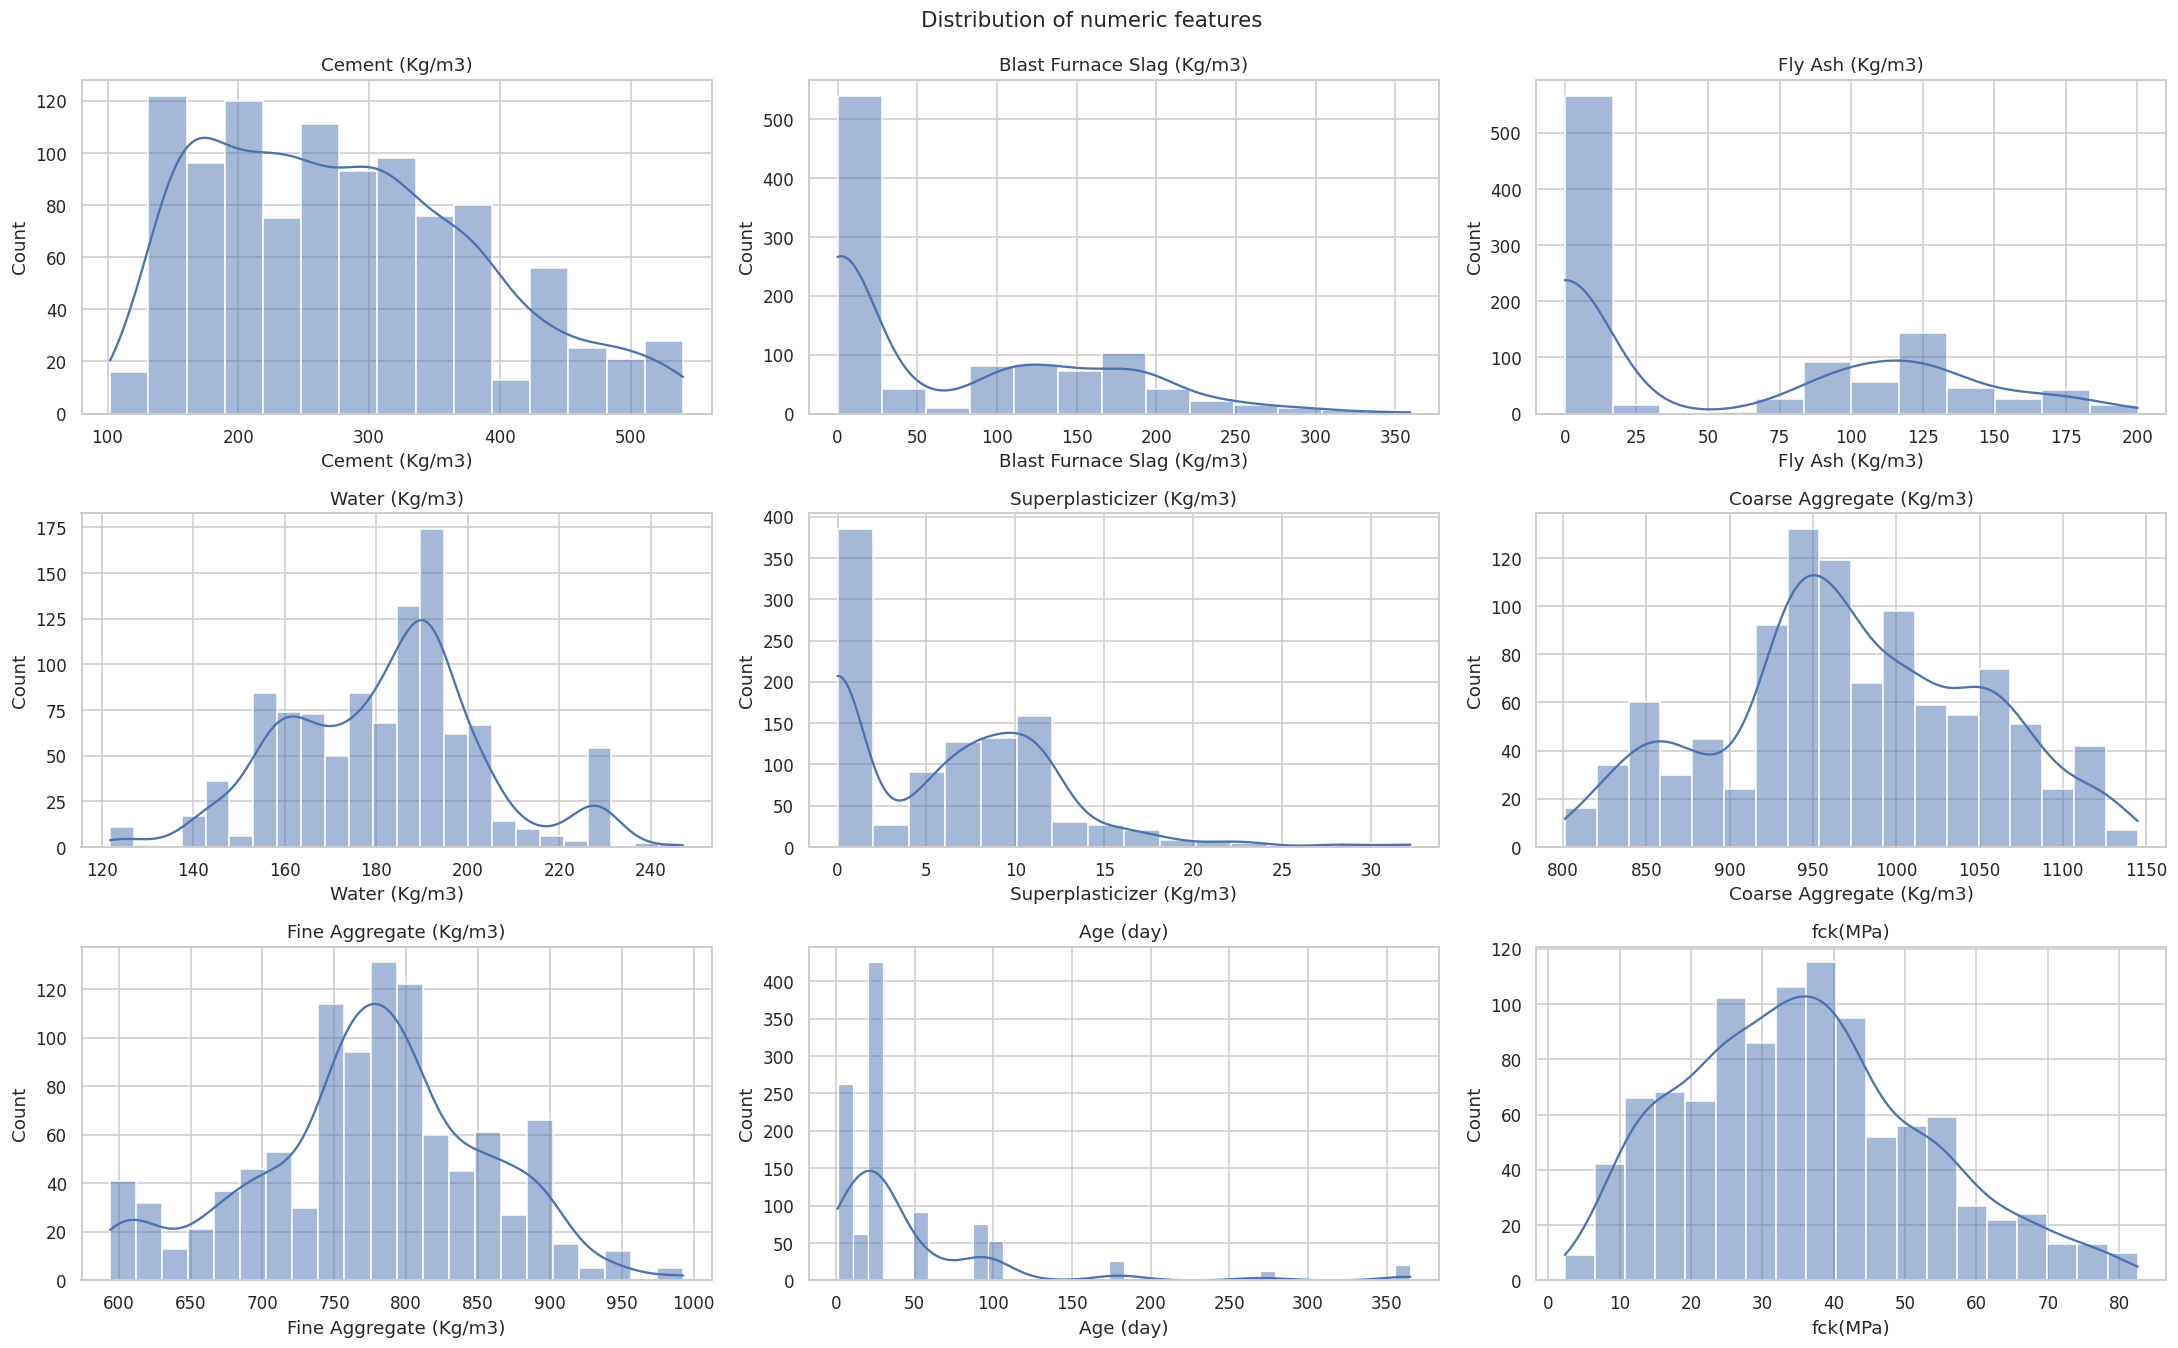

In [21]:
num_cols = FEATURES + [TARGET]

fig, axes = plt.subplots(3, 3, figsize=(20, 12)) # Adjusted for 9 columns
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.tight_layout()
plt.suptitle("Distribution of numeric features", y=1.02, fontsize=14)
plt.show()

Correlation heatmap

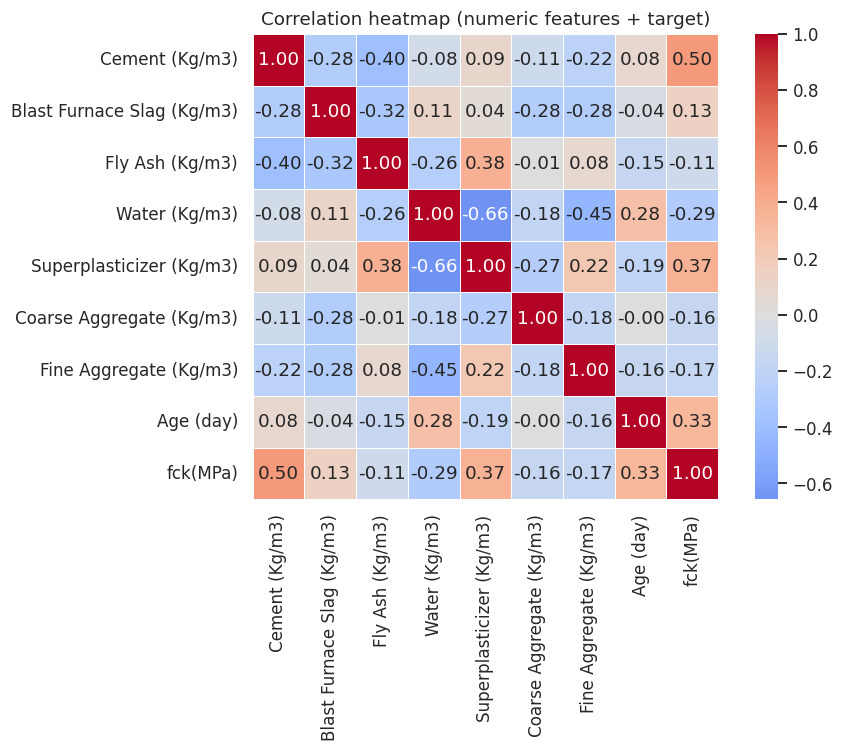

Correlation of each feature with fck(MPa), sorted:
Cement (Kg/m3)                0.497832
Superplasticizer (Kg/m3)      0.366079
Age (day)                     0.328873
Water (Kg/m3)                -0.289633
Fine Aggregate (Kg/m3)       -0.167241
Coarse Aggregate (Kg/m3)     -0.164935
Blast Furnace Slag (Kg/m3)    0.134829
Fly Ash (Kg/m3)              -0.105755
Name: fck(MPa), dtype: float64


In [22]:
plt.figure(figsize=(9, 7))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, square=True)
plt.title("Correlation heatmap (numeric features + target)")
plt.tight_layout()
plt.show()

print(f"Correlation of each feature with {TARGET}, sorted:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False))

Pairplot

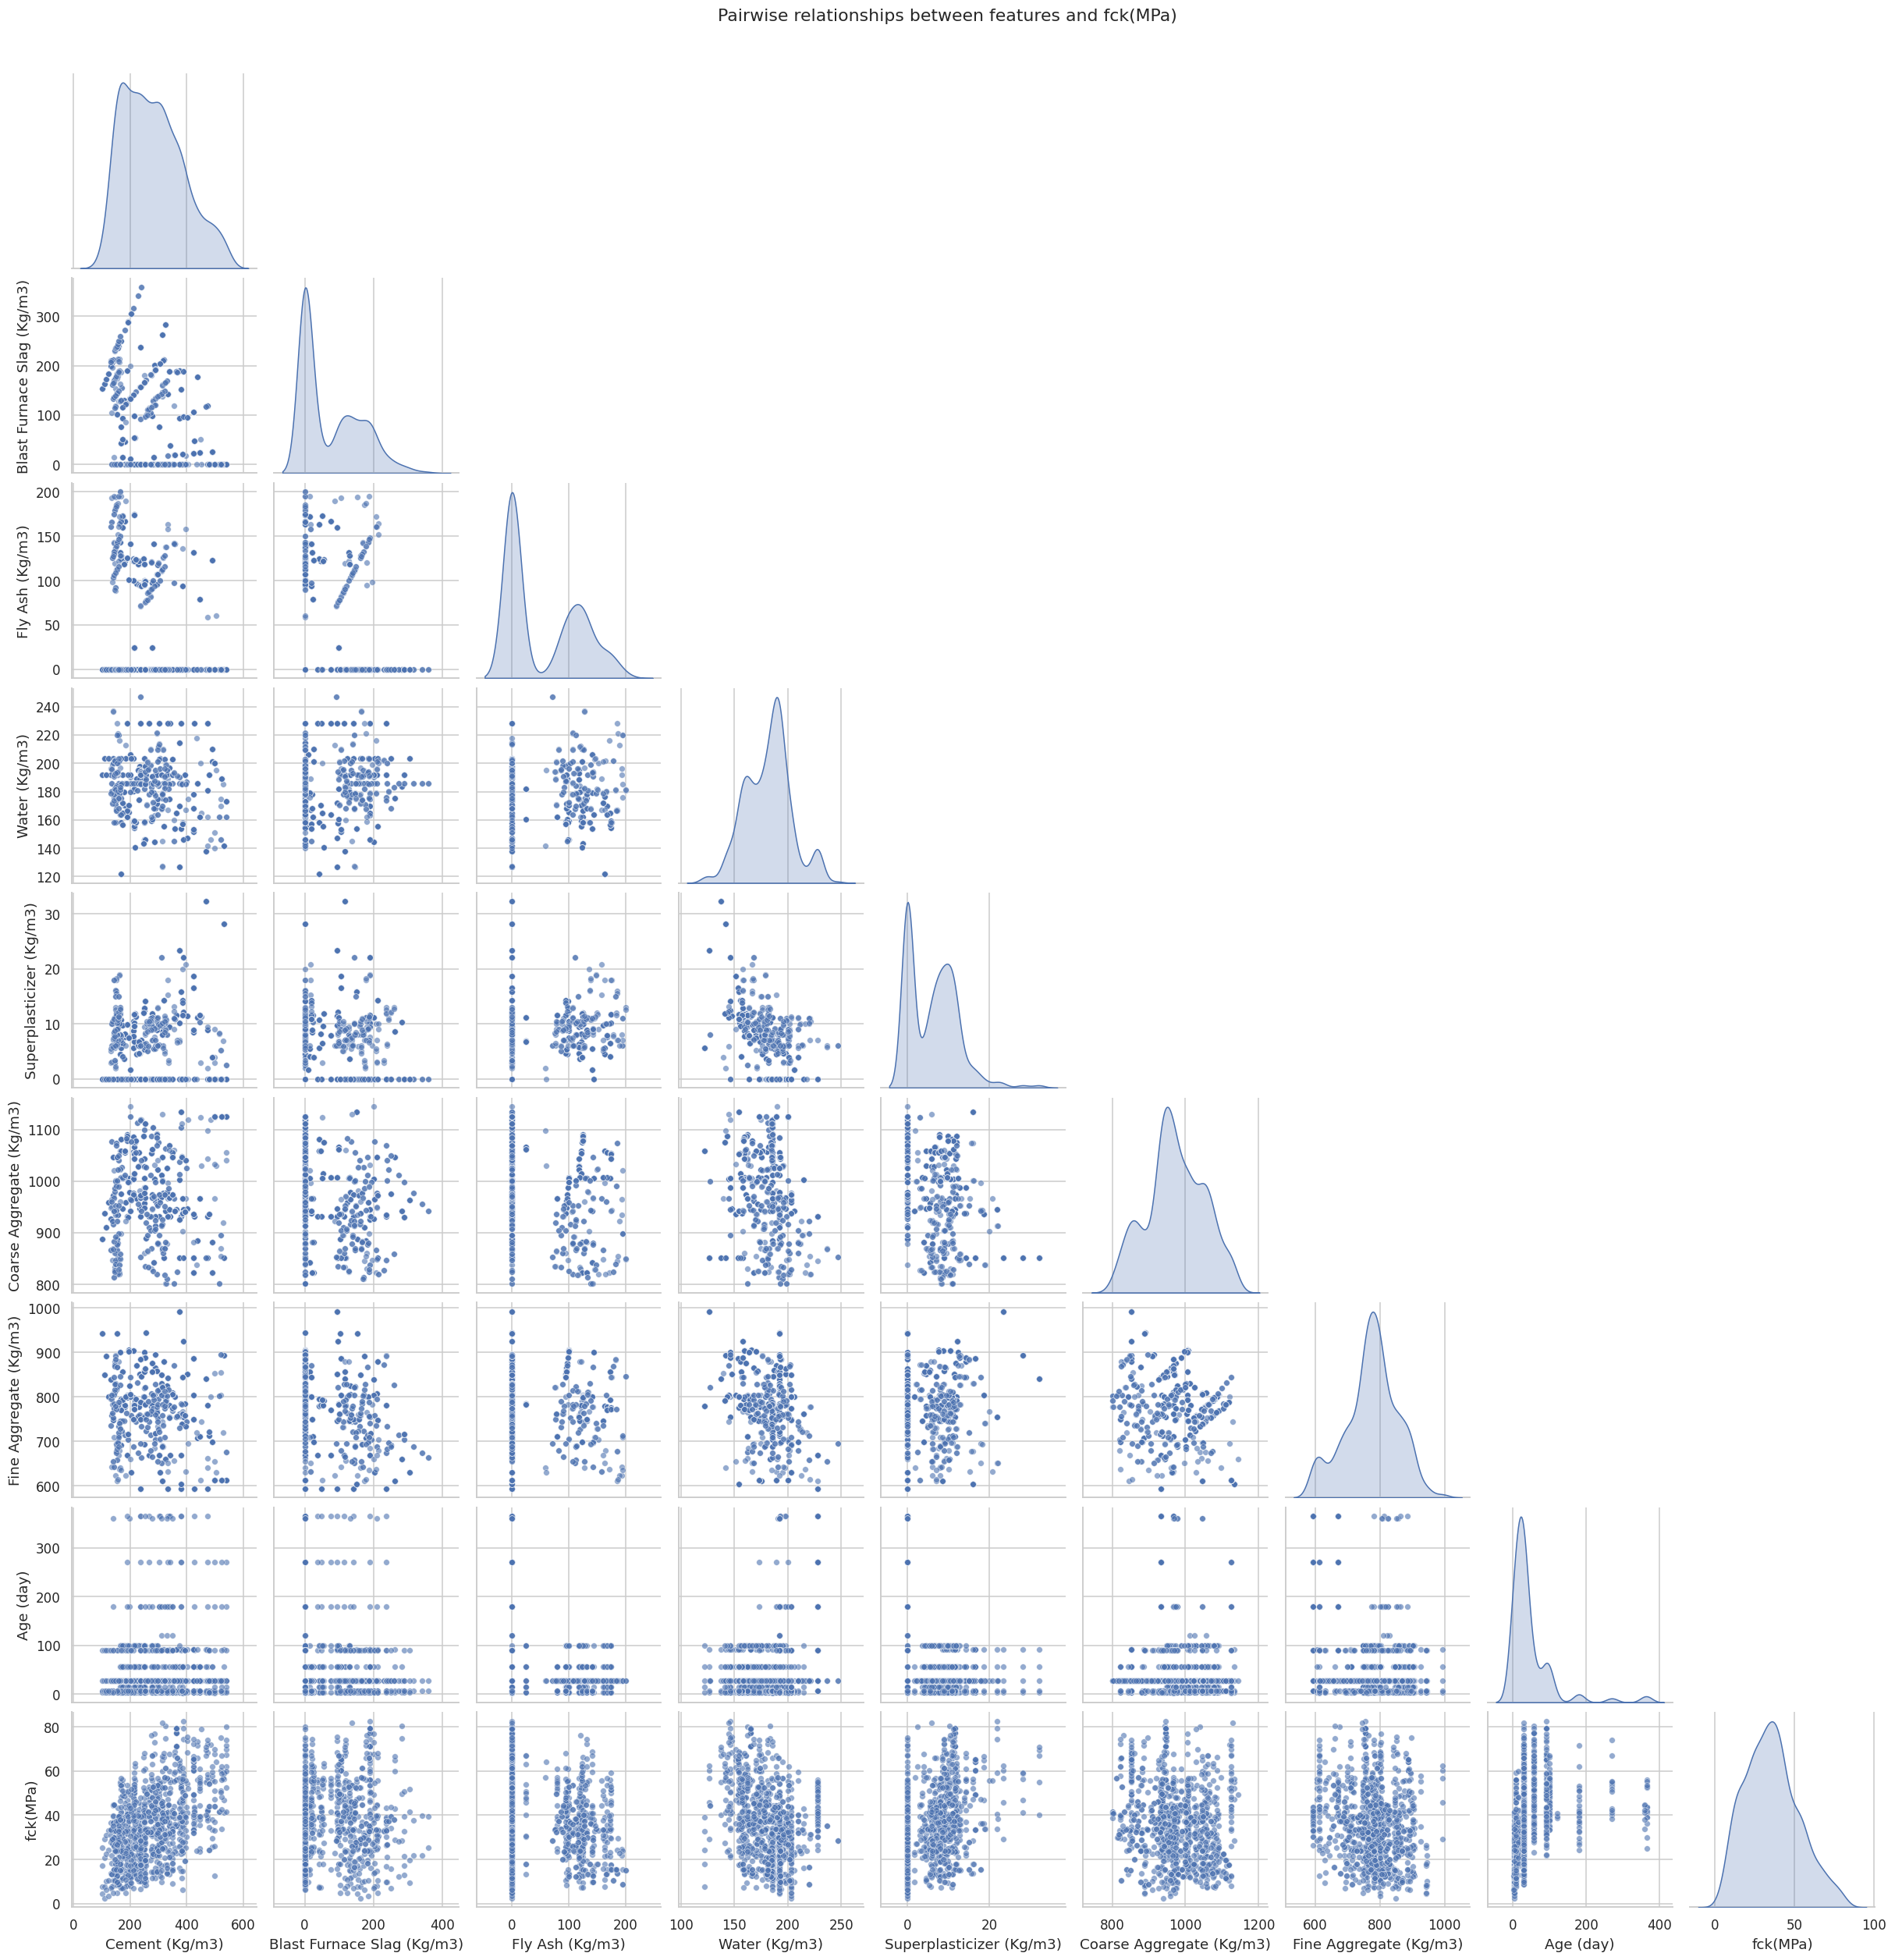

In [23]:
sns.pairplot(df[num_cols], corner=True, diag_kind="kde",
             plot_kws={"alpha": 0.6, "s": 25})
plt.suptitle(f"Pairwise relationships between features and {TARGET}", y=1.02)
plt.show()

Scatter plots

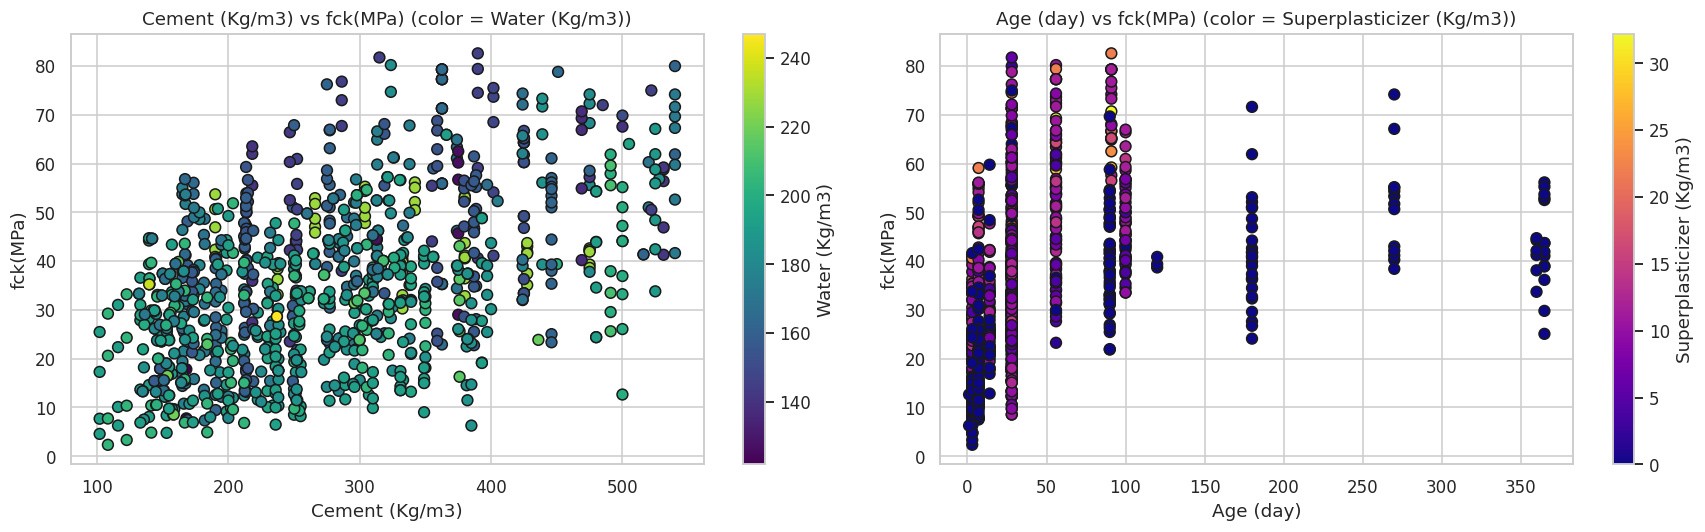

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Cement vs fck(MPa), colored by Water
sc = axes[0].scatter(df['Cement (Kg/m3)'], df['fck(MPa)'],
                      c=df['Water (Kg/m3)'], cmap="viridis", s=50, edgecolor='k')
axes[0].set_xlabel("Cement (Kg/m3)")
axes[0].set_ylabel("fck(MPa)")
axes[0].set_title("Cement (Kg/m3) vs fck(MPa) (color = Water (Kg/m3))")
plt.colorbar(sc, ax=axes[0], label="Water (Kg/m3)")

# Age vs fck(MPa), colored by Superplasticizer
sc2 = axes[1].scatter(df['Age (day)'], df['fck(MPa)'],
                       c=df['Superplasticizer (Kg/m3)'], cmap="plasma", s=50, edgecolor='k')
axes[1].set_xlabel("Age (day)")
axes[1].set_ylabel("fck(MPa)")
axes[1].set_title("Age (day) vs fck(MPa) (color = Superplasticizer (Kg/m3))")
plt.colorbar(sc2, ax=axes[1], label="Superplasticizer (Kg/m3)")

plt.tight_layout()
plt.show()

interpretation:
- `fck(MPa)` (compressive strength) correlates strongly with `Cement (Kg/m3)` and `Age (day)`, which is physically sensible.
- `Water (Kg/m3)` has a negative correlation, as higher water-cement ratios typically lead to lower strength.
- `Blast Furnace Slag` and `Fly Ash` can contribute to strength development over time, especially at later ages.
- Note the distributions of `Blast Furnace Slag`, `Fly Ash`, and `Superplasticizer` are skewed, indicating many mixes might not contain these components, or use them in smaller quantities. This suggests that the data might contain a mix of different concrete formulations.

Data cleaning

In [25]:
# 4.1 Duplicating rows
n_dupes = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dupes}")
df = df.drop_duplicates().reset_index(drop=True)

# 4.2 Outlier scan with IQR method
def iqr_outliers(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return (series < lo) | (series > hi)

outlier_report = pd.DataFrame({col: iqr_outliers(df[col]) for col in FEATURES + [TARGET]})
print("Outlier count per column (IQR method):")
print(outlier_report.sum())

flagged_rows = df[outlier_report.any(axis=1)]
print(f"\n{len(flagged_rows)} row(s) flagged as an outlier on at least one column:")
flagged_rows

Exact duplicate rows: 25
Outlier count per column (IQR method):
Cement (Kg/m3)                 0
Blast Furnace Slag (Kg/m3)     2
Fly Ash (Kg/m3)                0
Water (Kg/m3)                 15
Superplasticizer (Kg/m3)      10
Coarse Aggregate (Kg/m3)       0
Fine Aggregate (Kg/m3)         5
Age (day)                     59
fck(MPa)                       8
dtype: int64

94 row(s) flagged as an outlier on at least one column:


,Cement (Kg/m3),Blast Furnace Slag (Kg/m3),Fly Ash (Kg/m3),Water (Kg/m3),Superplasticizer (Kg/m3),Coarse Aggregate (Kg/m3),Fine Aggregate (Kg/m3),Age (day),fck(MPa)
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365,43.70
...,...,...,...,...,...,...,...,...,...
837,140.0,164.0,128.0,237.0,6.0,869.0,656.0,28,35.23
848,237.0,92.0,71.0,247.0,6.0,853.0,695.0,28,28.63
883,313.0,145.0,0.0,127.0,8.0,1000.0,822.0,28,44.52
911,236.9,91.7,71.5,246.9,6.0,852.9,695.4,28,28.63


Feature/target setup

In [29]:
FEATURES = NUM_FEATURES
TARGET = TARGETS[0]

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("X shape:", X.shape, "| y shape:", y.shape)
X.head()

X shape: (1005, 8) | y shape: (1005,)


,Cement (Kg/m3),Blast Furnace Slag (Kg/m3),Fly Ash (Kg/m3),Water (Kg/m3),Superplasticizer (Kg/m3),Coarse Aggregate (Kg/m3),Fine Aggregate (Kg/m3),Age (day)
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360


Train/test split

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (854, 8) Test: (151, 8)


Evaluation helper functions

In [34]:
def regression_scores(y_true, y_pred):
    '''Return a dict of standard regression metrics.'''
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

def evaluate_cv(model, X, y, cv=None, label=""):
    '''Repeated K-Fold cross-validation. Returns mean +/- std RMSE, MAE, R2.'''
    if cv is None:
        cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

    scoring = {
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
        "R2": "r2",
    }

    results = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)

    summary = {}
    for name in scoring:
        vals = results[f"test_{name}"]
        if name != "R2":
            vals = -vals  # neg_* scores are negative
        summary[f"{name}_mean"] = vals.mean()
        summary[f"{name}_std"] = vals.std()
    summary["model"] = label or model.__class__.__name__
    return summary

print_scores helper

In [35]:
def print_scores(name, scores_dict):
    print(f"{name:>20s} | RMSE: {scores_dict['RMSE_mean']:.4f} (+/-{scores_dict['RMSE_std']:.4f})")
    print(f"                     | MAE: {scores_dict['MAE_mean']:.4f} (+/-{scores_dict['MAE_std']:.4f})")
    print(f"                     | R2: {scores_dict['R2_mean']:.4f} (+/-{scores_dict['R2_std']:.4f})")

Define candidate models

In [36]:
def make_pipeline(model):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", model),
    ])

candidates = {
    "LinearRegression": make_pipeline(LinearRegression()),
    "Ridge": make_pipeline(Ridge(random_state=RANDOM_STATE)),
    "Lasso": make_pipeline(Lasso(random_state=RANDOM_STATE, max_iter=10000)),
    "ElasticNet": make_pipeline(ElasticNet(random_state=RANDOM_STATE, max_iter=10000)),
    "KNN": make_pipeline(KNeighborsRegressor()),
    "SVR": make_pipeline(SVR()),
    "RandomForest": make_pipeline(RandomForestRegressor(random_state=RANDOM_STATE)),
    "ExtraTrees": make_pipeline(ExtraTreesRegressor(random_state=RANDOM_STATE)),
    "GradientBoosting": make_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
}
if HAS_XGB:
    candidates["XGBoost"] = make_pipeline(
        XGBRegressor(random_state=RANDOM_STATE, verbosity=0)
    )

print("Candidate models defined:", list(candidates.keys()))

Candidate models defined: ['LinearRegression', 'Ridge', 'Lasso', 'ElasticNet', 'KNN', 'SVR', 'RandomForest', 'ExtraTrees', 'GradientBoosting', 'XGBoost']


Baseline cross-validated comparison

In [43]:
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

baseline_results = []
for name, pipe in candidates.items():
    scores = evaluate_cv(pipe, X_train, y_train, cv=cv, label=name)
    baseline_results.append(scores)
    print_scores(name, scores)

baseline_df = pd.DataFrame(baseline_results).set_index("model").sort_values("R2_mean", ascending=False)
baseline_df

    LinearRegression | RMSE: 10.2497 (+/-0.5545)
                     | MAE: 8.1302 (+/-0.4296)
                     | R2: 0.5951 (+/-0.0467)
               Ridge | RMSE: 10.2496 (+/-0.5524)
                     | MAE: 8.1373 (+/-0.4299)
                     | R2: 0.5952 (+/-0.0464)
               Lasso | RMSE: 10.8235 (+/-0.4930)
                     | MAE: 8.7615 (+/-0.4738)
                     | R2: 0.5495 (+/-0.0387)
          ElasticNet | RMSE: 11.5914 (+/-0.4905)
                     | MAE: 9.4306 (+/-0.4548)
                     | R2: 0.4842 (+/-0.0281)
                 KNN | RMSE: 9.3254 (+/-0.5507)
                     | MAE: 7.0997 (+/-0.3961)
                     | R2: 0.6646 (+/-0.0422)
                 SVR | RMSE: 10.2055 (+/-0.4953)
                     | MAE: 7.9761 (+/-0.4263)
                     | R2: 0.6004 (+/-0.0232)
        RandomForest | RMSE: 5.3277 (+/-0.4313)
                     | MAE: 3.7603 (+/-0.2598)
                     | R2: 0.8904 (+/-0.0171)
        

,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std
model,,,,,,
XGBoost,4.991061,0.442491,3.348290,0.247193,0.903519,0.018145
ExtraTrees,5.174401,0.516008,3.399449,0.302718,0.896265,0.020094
RandomForest,5.327700,0.431283,3.760313,0.259817,0.890380,0.017145
GradientBoosting,5.339872,0.351086,3.928517,0.239344,0.889926,0.015508
KNN,9.325445,0.550734,7.099728,0.396074,0.664609,0.042185
SVR,10.205545,0.495274,7.976072,0.426322,0.600358,0.023244
Ridge,10.249602,0.552386,8.137324,0.429889,0.595171,0.046359
LinearRegression,10.249674,0.554514,8.130241,0.429565,0.595143,0.046653
Lasso,10.823469,0.493018,8.761483,0.473763,0.549451,0.038698


Baseline comparison plot

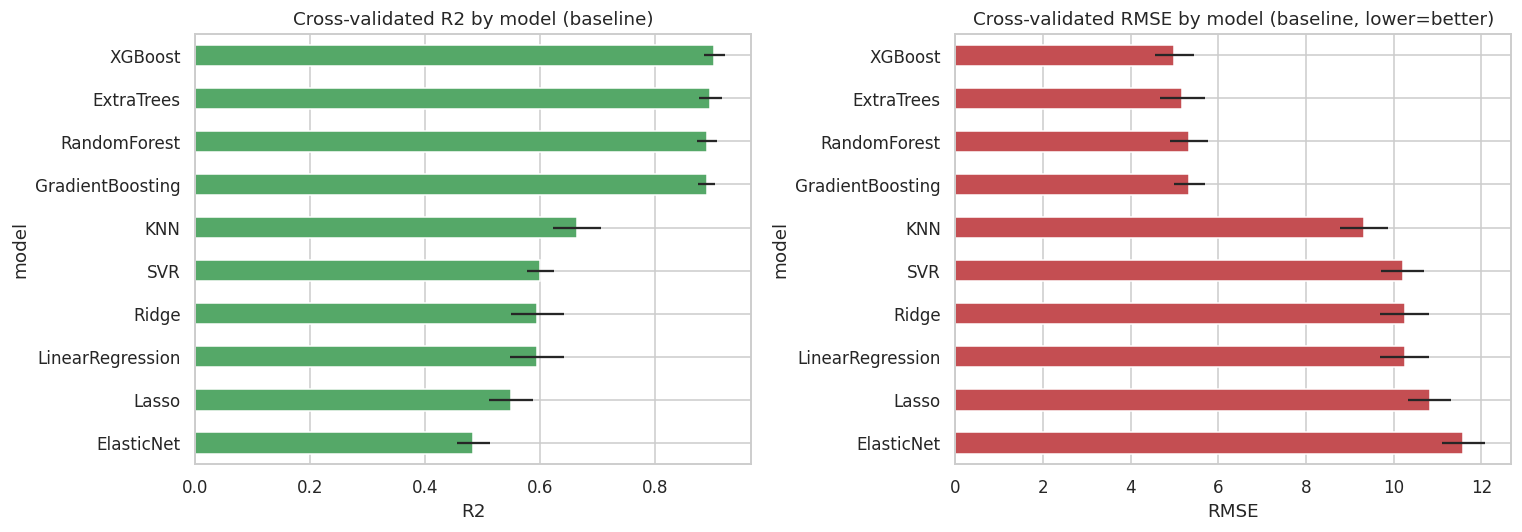

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

baseline_df["R2_mean"].sort_values().plot(kind="barh", ax=axes[0],
    xerr=baseline_df.loc[baseline_df["R2_mean"].sort_values().index, "R2_std"],
    color="#55A868")
axes[0].set_title("Cross-validated R2 by model (baseline)")
axes[0].set_xlabel("R2")

baseline_df["RMSE_mean"].sort_values(ascending=False).plot(kind="barh", ax=axes[1],
    xerr=baseline_df.loc[baseline_df["RMSE_mean"].sort_values(ascending=False).index, "RMSE_std"],
    color="#C44E52")
axes[1].set_title("Cross-validated RMSE by model (baseline, lower=better)")
axes[1].set_xlabel("RMSE")

plt.tight_layout()
plt.show()

Hyperparameter tuning

In [45]:
param_grids = {
    "Ridge": {"model__alpha": np.logspace(-3, 3, 30)},
    "Lasso": {"model__alpha": np.logspace(-4, 1, 30)},
    "ElasticNet": {"model__alpha": np.logspace(-4, 1, 20),
                   "model__l1_ratio": np.linspace(0.05, 0.95, 10)},
    "KNN": {"model__n_neighbors": list(range(2, 15)),
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]},
    "SVR": {"model__C": np.logspace(-2, 3, 20),
            "model__epsilon": [0.01, 0.05, 0.1, 0.2],
            "model__kernel": ["rbf", "linear"],
            "model__gamma": ["scale", "auto"]},
    "RandomForest": {"model__n_estimators": [100, 200, 400],
                      "model__max_depth": [None, 3, 5, 8, 12],
                      "model__min_samples_leaf": [1, 2, 3, 5],
                      "model__max_features": ["sqrt", "log2", 1.0]},
    "ExtraTrees": {"model__n_estimators": [100, 200, 400],
                   "model__max_depth": [None, 3, 5, 8, 12],
                   "model__min_samples_leaf": [1, 2, 3, 5]},
    "GradientBoosting": {"model__n_estimators": [100, 200, 400],
                          "model__max_depth": [2, 3, 4],
                          "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
                          "model__subsample": [0.7, 0.85, 1.0]},
}
if HAS_XGB:
    param_grids["XGBoost"] = {
        "model__n_estimators": [100, 200, 400],
        "model__max_depth": [2, 3, 4, 5],
        "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0],
    }


In [46]:
tuned_models = {}
tuning_results = []
inner_cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

for name, pipe in candidates.items():
    if name == "LinearRegression":
        tuned_models[name] = pipe.fit(X_train, y_train)
        scores = evaluate_cv(pipe, X_train, y_train, cv=cv, label=name)
        tuning_results.append(scores)
        continue

    grid = param_grids[name]
    n_iter = min(40, int(np.prod([len(v) for v in grid.values()])))
    search = RandomizedSearchCV(
        pipe, grid, n_iter=n_iter, cv=inner_cv, scoring="r2",
        random_state=RANDOM_STATE, n_jobs=-1
    )
    search.fit(X_train, y_train)
    best_pipe = search.best_estimator_
    tuned_models[name] = best_pipe

    scores = evaluate_cv(best_pipe, X_train, y_train, cv=cv, label=name)
    tuning_results.append(scores)
    print(f"{name:>20s} | best params: {search.best_params_}")
    print_scores(name, scores)

tuned_df = pd.DataFrame(tuning_results).set_index("model").sort_values("R2_mean", ascending=False)
tuned_df

               Ridge | best params: {'model__alpha': np.float64(1.2689610031679222)}
               Ridge | RMSE: 10.2497 (+/-0.5518)
                     | MAE: 8.1392 (+/-0.4300)
                     | R2: 0.5952 (+/-0.0463)
               Lasso | best params: {'model__alpha': np.float64(0.0001)}
               Lasso | RMSE: 10.2497 (+/-0.5545)
                     | MAE: 8.1303 (+/-0.4296)
                     | R2: 0.5951 (+/-0.0467)
          ElasticNet | best params: {'model__l1_ratio': np.float64(0.5499999999999999), 'model__alpha': np.float64(0.00206913808111479)}
          ElasticNet | RMSE: 10.2497 (+/-0.5530)
                     | MAE: 8.1357 (+/-0.4299)
                     | R2: 0.5952 (+/-0.0464)
                 KNN | best params: {'model__weights': 'distance', 'model__p': 2, 'model__n_neighbors': 5}
                 KNN | RMSE: 8.5507 (+/-0.5674)
                     | MAE: 6.2376 (+/-0.4151)
                     | R2: 0.7176 (+/-0.0400)
                 SVR | best par

,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std
model,,,,,,
XGBoost,4.518277,0.426561,3.037950,0.210046,0.920790,0.015647
GradientBoosting,4.602180,0.389878,3.156112,0.198930,0.917751,0.016079
ExtraTrees,5.174401,0.516008,3.399449,0.302718,0.896265,0.020094
RandomForest,5.327700,0.431283,3.760313,0.259817,0.890380,0.017145
SVR,5.892680,0.562825,4.043612,0.333993,0.865173,0.027081
KNN,8.550700,0.567372,6.237639,0.415098,0.717620,0.040037
Ridge,10.249725,0.551842,8.139193,0.429970,0.595167,0.046284
ElasticNet,10.249651,0.552988,8.135660,0.429864,0.595162,0.046432
LinearRegression,10.249674,0.554514,8.130241,0.429565,0.595143,0.046653


Comparing baseline vs tuned

In [47]:
comparison = baseline_df[["R2_mean", "RMSE_mean"]].join(
    tuned_df[["R2_mean", "RMSE_mean"]], lsuffix="_baseline", rsuffix="_tuned"
)
comparison

,R2_mean_baseline,RMSE_mean_baseline,R2_mean_tuned,RMSE_mean_tuned
model,,,,
XGBoost,0.903519,4.991061,0.920790,4.518277
ExtraTrees,0.896265,5.174401,0.896265,5.174401
RandomForest,0.890380,5.327700,0.890380,5.327700
GradientBoosting,0.889926,5.339872,0.917751,4.602180
KNN,0.664609,9.325445,0.717620,8.550700
SVR,0.600358,10.205545,0.865173,5.892680
Ridge,0.595171,10.249602,0.595167,10.249725
LinearRegression,0.595143,10.249674,0.595143,10.249674
Lasso,0.549451,10.823469,0.595143,10.249679


Final ranking plot

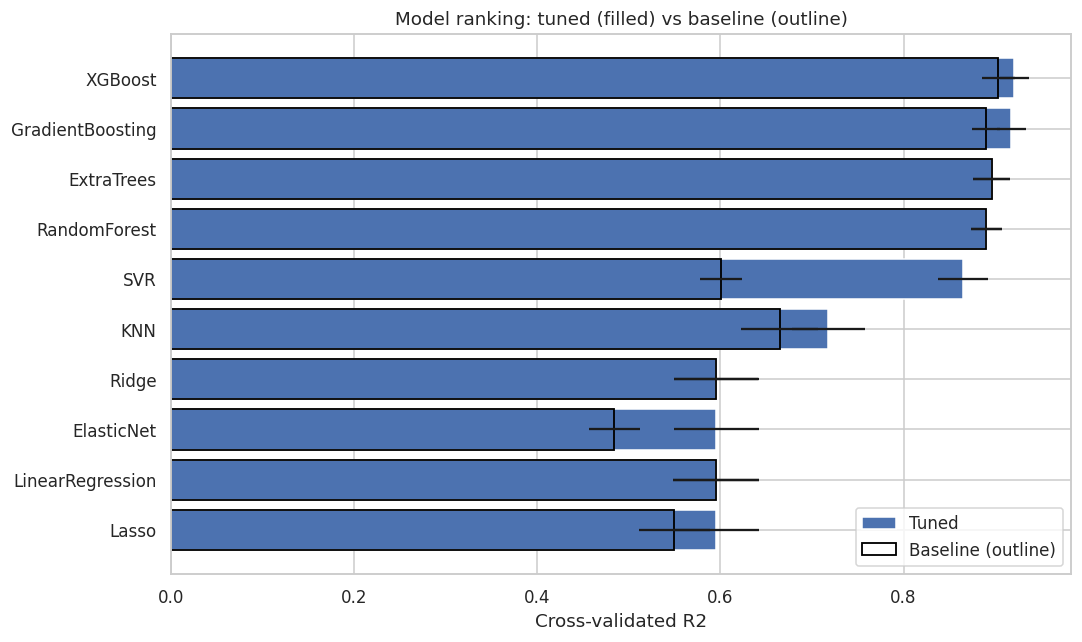

In [48]:
plt.figure(figsize=(10, 6))
order = tuned_df.sort_values("R2_mean").index

plt.barh(order, tuned_df.loc[order, "R2_mean"], xerr=tuned_df.loc[order, "R2_std"],
         color="#4C72B0", label="Tuned")
plt.barh(order, baseline_df.loc[order, "R2_mean"], xerr=baseline_df.loc[order, "R2_std"],
         color="none", edgecolor="black", linewidth=1.2, label="Baseline (outline)")

plt.xlabel("Cross-validated R2")
plt.title("Model ranking: tuned (filled) vs baseline (outline)")
plt.legend()
plt.tight_layout()
plt.show()

In [49]:
BEST_NAME = tuned_df["R2_mean"].idxmax()
best_model = tuned_models[BEST_NAME]
print("Selected best model (highest cross-validated R2):", BEST_NAME)
print(tuned_df.loc[BEST_NAME])

Selected best model (highest cross-validated R2): XGBoost
RMSE_mean    4.518277
RMSE_std     0.426561
MAE_mean     3.037950
MAE_std      0.210046
R2_mean      0.920790
R2_std       0.015647
Name: XGBoost, dtype: float64


In [50]:
best_model.fit(X_train, y_train)
y_pred_test = best_model.predict(X_test)
holdout_scores = regression_scores(y_test, y_pred_test)
print(f"Hold-out test performance for {BEST_NAME}:")
for k, v in holdout_scores.items():
    print(f"  {k}: {v:.4f}")

Hold-out test performance for XGBoost:
  RMSE: 3.9407
  MAE: 2.6250
  R2: 0.9434


Prediction vs actual + residual plots

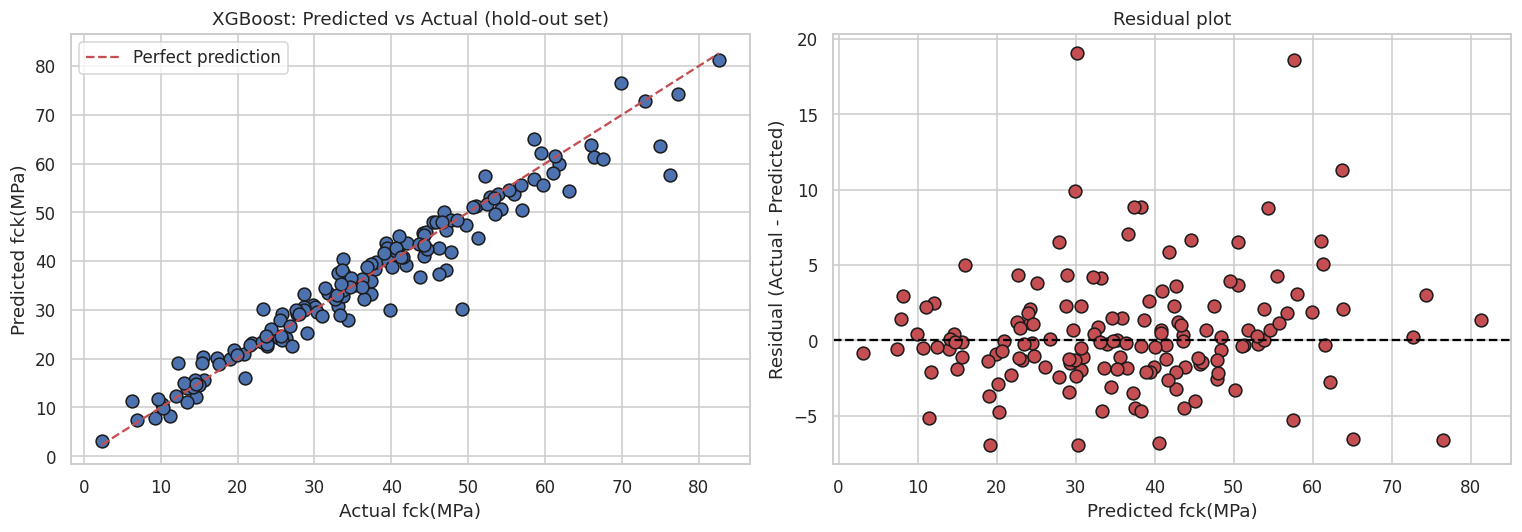

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_test, color="#4C72B0", edgecolor="k", s=70)
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual fck(MPa)")
axes[0].set_ylabel("Predicted fck(MPa)")
axes[0].set_title(f"{BEST_NAME}: Predicted vs Actual (hold-out set)")
axes[0].legend()

residuals = y_test.values - y_pred_test
axes[1].scatter(y_pred_test, residuals, color="#C44E52", edgecolor="k", s=70)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Predicted fck(MPa)")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual plot")

plt.tight_layout()
plt.show()

Final refit & export

In [52]:
final_model = tuned_models[BEST_NAME]
final_model.fit(X, y)

MODEL_PATH = "best_fck_model.joblib"
joblib.dump(
    {
        "model": final_model,
        "features": FEATURES,
        "target": TARGET,
        "model_name": BEST_NAME,
        "cv_r2_mean": float(tuned_df.loc[BEST_NAME, "R2_mean"]),
        "cv_rmse_mean": float(tuned_df.loc[BEST_NAME, "RMSE_mean"]),
    },
    MODEL_PATH,
)

print(f"Saved '{BEST_NAME}' pipeline (trained on all {len(X)} rows) to {MODEL_PATH}")

# Use within colab for importing the files :
# from google.colab import files
# files.download(MODEL_PATH)

Saved 'XGBoost' pipeline (trained on all 1005 rows) to best_fck_model.joblib


Using new dataset for model

In [53]:
def predict_fck(
    cement_kg_m3,
    blast_furnace_slag_kg_m3,
    fly_ash_kg_m3,
    water_kg_m3,
    superplasticizer_kg_m3,
    coarse_aggregate_kg_m3,
    fine_aggregate_kg_m3,
    age_day,
    model_path="best_fck_model.joblib",
):
    """
    Predict fck(MPa) for a new concrete mix design.
    """
    bundle = joblib.load(model_path)
    model = bundle["model"]
    features = bundle["features"]

    new_row = pd.DataFrame(
        [
            {
                "Cement (Kg/m3)": cement_kg_m3,
                "Blast Furnace Slag (Kg/m3)": blast_furnace_slag_kg_m3,
                "Fly Ash (Kg/m3)": fly_ash_kg_m3,
                "Water (Kg/m3)": water_kg_m3,
                "Superplasticizer (Kg/m3)": superplasticizer_kg_m3,
                "Coarse Aggregate (Kg/m3)": coarse_aggregate_kg_m3,
                "Fine Aggregate (Kg/m3)": fine_aggregate_kg_m3,
                "Age (day)": age_day,
            }
        ]
    )[features]

    pred = model.predict(new_row)[0]
    print(f"Model: {bundle['model_name']} (CV R2 ~ {bundle['cv_r2_mean']:.3f})")
    print(f"Predicted fck(MPa): {pred:.4f}")
    return pred

# Example usage — replace with your own mix design:
_ = predict_fck(
    cement_kg_m3=300,
    blast_furnace_slag_kg_m3=100,
    fly_ash_kg_m3=50,
    water_kg_m3=180,
    superplasticizer_kg_m3=8,
    coarse_aggregate_kg_m3=900,
    fine_aggregate_kg_m3=700,
    age_day=28,
)

Model: XGBoost (CV R2 ~ 0.921)
Predicted fck(MPa): 42.1448
